<a href="https://colab.research.google.com/github/OssamaSijbesma/uu-data-analysis-and-machine-learning-assignments/blob/main/assignment-2/report.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Assignment 2: Text clustering

Date: *15 october 2026*

Authors:
*   *Ossama Sijbesma (9890238)*
*   *Nóra Zala (8874905)*
*   *Rayana Sajith (9290184)*
*   *xxx*



In [17]:
%pip install --quiet sentence_transformers wordcloud seaborn

Note: you may need to restart the kernel to use updated packages.


In [122]:
# Import necessary libraries
import re

import matplotlib.pyplot as plt
import pandas as pd
from sentence_transformers import SentenceTransformer
from sklearn.cluster import KMeans
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import (
    adjusted_rand_score,
    calinski_harabasz_score,
    davies_bouldin_score,
    homogeneity_completeness_v_measure,
    normalized_mutual_info_score,
    silhouette_score,
)
from wordcloud import WordCloud

# Set global constants
RANDOM_SEED = 14
DATA_SOURCE = "https://raw.githubusercontent.com/OssamaSijbesma/uu-data-analysis-and-machine-learning-assignments/refs/heads/main/assignment-2/movie_review.csv"


In [10]:
# Fetch dataset from github
raw_dataset = pd.read_csv(DATA_SOURCE)
raw_dataset.head()

,id,sentiment,review
0,5814_8,1,With all this stuff going down at the moment w...
1,2381_9,1,"\""The Classic War of the Worlds\"" by Timothy H..."
2,7759_3,0,The film starts with a manager (Nicholas Bell)...
3,3630_4,0,It must be assumed that those who praised this...
4,9495_8,1,Superbly trashy and wondrously unpretentious 8...


## Data description

Describe the data and use a visualization to support your story. (approx. one or two paragraphs)

In [11]:
reviews = raw_dataset["review"].tolist()
split_words = raw_dataset["review"].str.split()

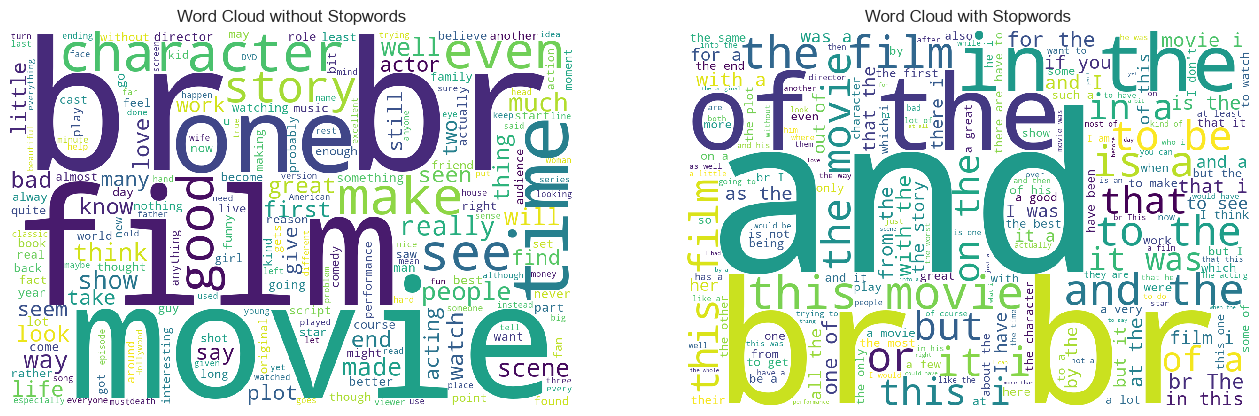

In [107]:
# Create a word cloud with and without stopwords
all_reviews_text = " ".join(reviews)

wordcloud_with_stopwords = WordCloud(
    width=1200, height=800, background_color="white", stopwords=set()
).generate(all_reviews_text)

wordcloud = WordCloud(
    width=1200, height=800, background_color="white", stopwords=None
).generate(all_reviews_text)

plt.figure(figsize=(16, 8))

plt.subplot(1, 2, 1)
plt.imshow(wordcloud, interpolation="nearest")
plt.axis("off")
plt.title("Word Cloud without Stopwords")

plt.subplot(1, 2, 2)
plt.imshow(wordcloud_with_stopwords, interpolation="nearest")
plt.axis("off")
plt.title("Word Cloud with Stopwords")

plt.show()

Something about the difference and how br is still present in the word cloud without stopwords.

In [12]:
# Min, Max, average, and total number of words in the reviews
word_counts = split_words.str.len()
min_words = word_counts.min()
max_words = word_counts.max()
average_words = int(word_counts.mean())
median_words = int(word_counts.median())
total_words = word_counts.sum()

print("Minimum number of words:", min_words)
print("Maximum number of words:", max_words)
print("Average number of words:", average_words)
print("Median number of words:", median_words)
print("Total number of words:", total_words)

Minimum number of words: 12
Maximum number of words: 2470
Average number of words: 237
Median number of words: 177
Total number of words: 1186896


C:\Users\ossam\AppData\Local\Temp\ipykernel_19344\1058742821.py:4: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  box = ax.boxplot(


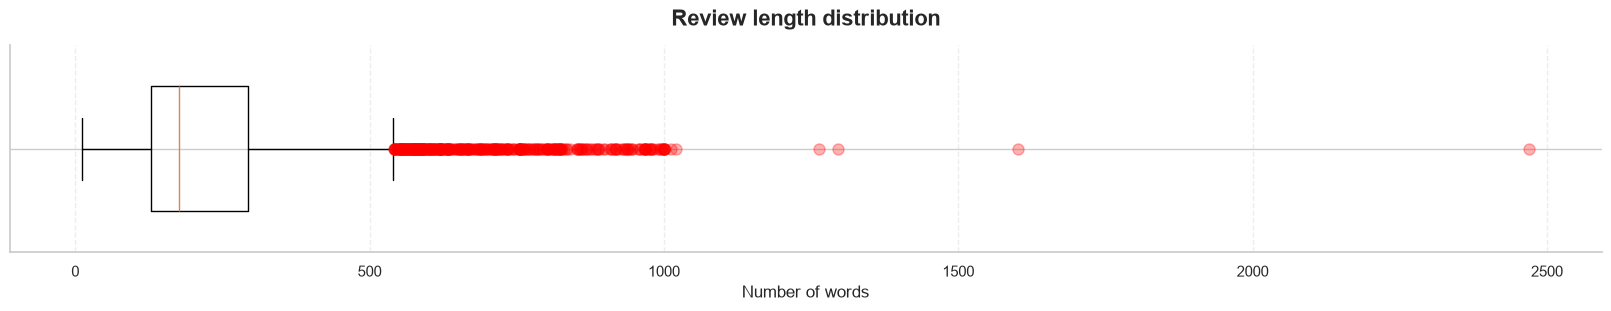

In [89]:
# Box plot showing the distribution of review lengths in terms of word count
fig, ax = plt.subplots(figsize=(16, 3), constrained_layout=True)

box = ax.boxplot(
    word_counts,
    vert=False,
    widths=0.6,
    flierprops={
        "marker": "o",
        "markerfacecolor": "red",
        "markeredgecolor": "red",
        "alpha": 0.3,
        "markersize": 8,
    },
)

ax.set_title("Review length distribution", fontsize=16, weight="bold", pad=14)
ax.set_xlabel("Number of words", fontsize=12)
ax.set_yticklabels([""])
ax.set_axisbelow(True)
ax.xaxis.grid(True, linestyle="--", alpha=0.35)
ax.spines[["top", "right"]].set_visible(False)
plt.show()

In [103]:
# Check out the eight largest reviews
print("The eight largest reviews are:")
for review in sorted(reviews, key=lambda x: len(x.split()), reverse=True)[:8]:
    print(
        f"Review #{reviews.index(review) + 1} ({len(review.split())} words) - {review}"
    )

The eight largest reviews are:
Review #3486 (2470 words) - Match 1: Tag Team Table Match Bubba Ray and Spike Dudley vs Eddie Guerrero and Chris Benoit Bubba Ray and Spike Dudley started things off with a Tag Team Table Match against Eddie Guerrero and Chris Benoit. According to the rules of the match, both opponents have to go through tables in order to get the win. Benoit and Guerrero heated up early on by taking turns hammering first Spike and then Bubba Ray. A German suplex by Benoit to Bubba took the wind out of the Dudley brother. Spike tried to help his brother, but the referee restrained him while Benoit and Guerrero ganged up on him in the corner. With Benoit stomping away on Bubba, Guerrero set up a table outside. Spike dashed into the ring and somersaulted over the top rope onto Guerrero on the outside! After recovering and taking care of Spike, Guerrero slipped a table into the ring and helped the Wolverine set it up. The tandem then set up for a double superplex from the mi

In [104]:
# Check out the eight shortest reviews
print("The eight shortest reviews are:")
for review in sorted(reviews, key=lambda x: len(x.split()))[:8]:
    print(
        f"Review #{reviews.index(review) + 1} ({len(review.split())} words) - {review}"
    )

The eight shortest reviews are:
Review #4049 (12 words) - Adrian Pasdar is excellent is this film. He makes a fascinating woman.
Review #3770 (19 words) - The characters are unlikeable and the script is awful. It's a waste of the talents of Deneuve and Auteuil.
Review #1203 (25 words) - Kept my attention from start to finish. Great performances added to this tremendous film. Mr. Pacino once again gives us another brilliant character to enjoy.
Review #2300 (25 words) - Much underrated camp movie on the level of Cobra Woman, etc. Photographic stills resemble Rembrandt prints. Sometimes subtle dialog and hidden literate touches found throughout.
Review #136 (26 words) - This is without a doubt the worst movie I have ever seen. It is not funny. It is not interesting and should not have been made.
Review #1185 (27 words) - Brilliant execution in displaying once and for all, this time in the venue of politics, of how \"good intentions do actually pave the road to hell\". Excellent!
Review #3

One outlier really jumps out from the rest. Looking at the review, it’s a detailed match-by-match report of WWE Vengeance 2002. While unusually long for a review, it still clearly acts as one therefore I’d classify it as a global outlier rather than a contextual outlier.

The next review is substantially shorter than our most extreme case, but it still stands out as a major outlier when looking at the rest of the data. It isn't until we reach the fifth review that the entries stop "feeling" like outliers. While all of these entries are legitimate reviews, their sheer size could cause issues later on with text representation methods and/or clustering methods.

On the other end of the distribution, the reviews are fairly standard, staying close to the mean and free of any foreseeable problems.

# Text pre-processing

Describe text pre-processing steps you have used (approx. one or two paragraphs)Data description$0

In [112]:
# Define a custom text preprocessor for cleaning movie reviews
# It is used later in the text vectorization process
def custom_preprocessor(text):
    # 1. Convert text to lowercase
    text = text.lower()
    # 2. Remove HTML tags (e.g., <br />)
    text = re.sub(r"<[^>]*>", "", text)
    # 3. Remove spoiler tags (e.g., [spoiler])
    text = re.sub(r"\[spoiler\]", "", text)
    # Return cleaned text
    return text

## Text representaion

Briefly describe your text representation method. (approx. one or two paragraphs)

In [108]:
# model = SentenceTransformer("all-MiniLM-L6-v2") # doesn't work with long texts
# embeddings = model.encode(raw_dataset["review"].tolist())

In [115]:
# Instantiate vectorizer (automatically lowercases and handles basic stop words)
tfidf_vectorizer = TfidfVectorizer(
    ngram_range=(1, 2),  # Unigrams + Bigrams
    min_df=3,  # Ignore phrases appearing in fewer than 3 reviews
    max_df=0.80,  # Ignore corpus-wide words appearing in >80% of reviews (e.g., "movie", "film")
    stop_words="english",  # Remove stop words
    sublinear_tf=True,  # Apply 1 + log(tf) scaling to dampen word repetition in 3,000-word texts
    preprocessor=custom_preprocessor,  # Apply custom text cleaning before vectorization
)

# Learn vocabulary and transform corpus into sparse matrix
tfidf_matrix = tfidf_vectorizer.fit_transform(reviews)

# Extract feature names (vocabulary)
feature_names = tfidf_vectorizer.get_feature_names_out()

# Convert to Dense DataFrame for display
df_tfidf = pd.DataFrame(tfidf_matrix.toarray(), columns=feature_names)
print(df_tfidf)

       00       000  000 000  007  00pm   01   02   07        10    10 000  \
0     0.0  0.000000      0.0  0.0   0.0  0.0  0.0  0.0  0.000000  0.000000   
1     0.0  0.000000      0.0  0.0   0.0  0.0  0.0  0.0  0.000000  0.000000   
2     0.0  0.062694      0.0  0.0   0.0  0.0  0.0  0.0  0.033081  0.081336   
3     0.0  0.000000      0.0  0.0   0.0  0.0  0.0  0.0  0.000000  0.000000   
4     0.0  0.000000      0.0  0.0   0.0  0.0  0.0  0.0  0.000000  0.000000   
...   ...       ...      ...  ...   ...  ...  ...  ...       ...       ...   
4995  0.0  0.000000      0.0  0.0   0.0  0.0  0.0  0.0  0.000000  0.000000   
4996  0.0  0.000000      0.0  0.0   0.0  0.0  0.0  0.0  0.104236  0.000000   
4997  0.0  0.000000      0.0  0.0   0.0  0.0  0.0  0.0  0.000000  0.000000   
4998  0.0  0.000000      0.0  0.0   0.0  0.0  0.0  0.0  0.000000  0.000000   
4999  0.0  0.000000      0.0  0.0   0.0  0.0  0.0  0.0  0.000000  0.000000   

      ...  zombie make  zombie movie  zombie movies  zombies  z

## Text clustering

Briefly describe which models you compare to perform clustering. (approx. two or three paragraphs)

### K-Means

In [ ]:
# Create KMeans clustering models for 5 and 10 clusters
k5means = KMeans(n_clusters=5, random_state=RANDOM_SEED, n_init=10)
k10means = KMeans(n_clusters=10, random_state=RANDOM_SEED, n_init=10)

# Label the documents with the cluster assignments
k5m_cluster_labels = k5means.fit_predict(tfidf_matrix)
k10m_cluster_labels = k10means.fit_predict(tfidf_matrix)

In [ ]:
# Perform internal validation
k5_sil_score = silhouette_score(tfidf_matrix, k5m_cluster_labels)
k5_db_score = davies_bouldin_score(tfidf_matrix.toarray(), k5m_cluster_labels)
k5_ch_score = calinski_harabasz_score(tfidf_matrix.toarray(), k5m_cluster_labels)


# Perform internal validation for 10 clusters
k10_sil_score = silhouette_score(tfidf_matrix, k10m_cluster_labels)
k10_db_score = davies_bouldin_score(tfidf_matrix.toarray(), k10m_cluster_labels)
k10_ch_score = calinski_harabasz_score(tfidf_matrix.toarray(), k10m_cluster_labels)

# Print as pandas DataFrame
validation_df = pd.DataFrame(
    {
        "Clusters": ["5", "10"],
        "Silhouette": [k5_sil_score, k10_sil_score],
        "Davies-Bouldin": [k5_db_score, k10_db_score],
        "Calinski-Harabasz": [k5_ch_score, k10_ch_score],
    },
)

print(validation_df.to_string(index=False))

Clusters  Silhouette  Davies-Bouldin  Calinski-Harabasz
       5    0.000721       22.299764           5.005364
      10    0.000661       19.941129           3.427609


In [ ]:
ari = adjusted_rand_score(k5m_cluster_labels, k10m_cluster_labels)
nmi = normalized_mutual_info_score(k5m_cluster_labels, k10m_cluster_labels)
homo, comp, v_measure = homogeneity_completeness_v_measure(
    k5m_cluster_labels, k10m_cluster_labels
)

print(f"Adjusted Rand Index: {ari}")
print(f"Normalized Mutual Information: {nmi}")
print(f"Homogeneity: {homo}")
print(f"Completeness: {comp}")
print(f"V-Measure: {v_measure}")

Adjusted Rand Index: 0.2892969220870035
Normalized Mutual Information: 0.3483473127881498
Homogeneity: 0.42385467357420026
Completeness: 0.2956745334903736
V-Measure: 0.3483473127881498


## Evaluation & model comparison

Describe how you compare the methods and why. (approx. two or three paragraphs)

## Team member contributions

*   Ossama Sijbesma: data description, pre-processing, text representation, text clustering
*   Nóra Zala: